# Task 2 – Exploratory Data Analysis

## Project Overview

This notebook performs Exploratory Data Analysis (EDA) on the cleaned AI Job Market dataset prepared during Task 1 of the SWYNEX internship project.

The objective of this analysis is to understand the structure of the job market dataset, identify important trends and patterns, analyze relationships between variables, detect potential anomalies, and generate useful data-driven insights.

The analysis will focus on:

- Job posting distribution
- AI-related vs non-AI-related jobs
- Job categories
- Geographic distribution
- Contract types and working arrangements
- Salary patterns
- Relationships between job characteristics
- Trends and anomalies

The cleaned dataset from Task 1 will be used as the input for this analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Display setthings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

#Set plotting style
sns.set_theme(style="whitegrid")

## 2. Load Cleaned Dataset

The cleaned dataset generated during Task 1 is loaded from the `data/cleaned/` directory.

The raw dataset is not used for this analysis because the objective of Task 2 is to perform exploratory analysis on the cleaned and validated dataset.

In [2]:
#Load the cleaned dataset
file_path = "../data/cleaned/ai_job_market_cleaned.csv"
df = pd.read_csv(file_path)
df.head()

,search_keyword,search_country,id,title,company,location,category,contract_type,contract_time,salary_min,salary_max,salary_is_predicted,created,description,is_ai_related,salary_avg,created_date,currency,country_name
0,artificial intelligence,gb,5822242641,Senior Technologist Artificial Intelligence R ...,Hackajob Ltd,"Great Baddow, Chelmsford",Engineering Jobs,permanent,NaN,40000.00,40000.00,0,2026-07-31 11:09:48+00:00,hackajob is partnering directly with BAE Syste...,True,40000.00,2026-07-31,GBP,United Kingdom
1,artificial intelligence,gb,5727313687,Artificial Intelligence,Adria Solutions,"Altrincham, Greater Manchester",IT Jobs,NaN,NaN,53702.83,53702.83,1,2026-05-12 22:05:22+00:00,AI Engineer - Manchester - Circa £50K Our clie...,True,53702.83,2026-05-12,GBP,United Kingdom
2,artificial intelligence,gb,5736675451,Artificial Intelligence Engineer,Oxford Dynamics,UK,IT Jobs,permanent,full_time,74422.25,74422.25,1,2026-05-21 21:07:04+00:00,Artificial Intelligence Engineers Contract: Pe...,True,74422.25,2026-05-21,GBP,United Kingdom
3,artificial intelligence,gb,5824444000,Artificial Intelligence Engineer,Quantiphi,"London, UK",IT Jobs,NaN,full_time,53031.54,53031.54,1,2026-08-01 18:29:25+00:00,"While technology is the heart of our business,...",True,53031.54,2026-08-01,GBP,United Kingdom
4,artificial intelligence,gb,5844156514,Artificial Intelligence Engineer,Discover International,"Monument, Central London",IT Jobs,contract,full_time,52000.00,60000.00,0,2026-08-16 11:39:19+00:00,"Salary: £52,000 - 60,000 per year Requirements...",True,56000.00,2026-08-16,GBP,United Kingdom


In [3]:
df.shape

(1696, 19)

## 3. Dataset Overview

Before beginning the exploratory analysis, the structure of the cleaned dataset is examined.

The following checks will be performed:

- Dataset dimensions
- Column names
- Data types
- Missing values
- Numerical summary statistics

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1696
Number of columns: 19


In [5]:
#Columns names

df.columns.tolist()

['search_keyword',
 'search_country',
 'id',
 'title',
 'company',
 'location',
 'category',
 'contract_type',
 'contract_time',
 'salary_min',
 'salary_max',
 'salary_is_predicted',
 'created',
 'description',
 'is_ai_related',
 'salary_avg',
 'created_date',
 'currency',
 'country_name']

In [6]:
#Data types

df.dtypes

search_keyword             str
search_country             str
id                       int64
title                      str
company                    str
location                   str
category                   str
contract_type              str
contract_time              str
salary_min             float64
salary_max             float64
salary_is_predicted      int64
created                    str
description                str
is_ai_related             bool
salary_avg             float64
created_date               str
currency                   str
country_name               str
dtype: object

In [7]:
#Statistical summary of numerical columns

df.describe()

,id,salary_min,salary_max,salary_is_predicted,salary_avg
count,1.696000e+03,1.513000e+03,1.513000e+03,1696.000000,1.513000e+03
mean,5.771004e+09,7.729904e+04,8.727796e+04,0.684552,8.228850e+04
std,3.734309e+08,9.713633e+04,1.836966e+05,0.464831,1.375764e+05
min,1.155089e+09,0.000000e+00,1.300000e+01,0.000000,1.300000e+01
25%,5.805809e+09,3.488679e+04,3.504305e+04,0.000000,3.500000e+04
50%,5.830417e+09,5.460000e+04,5.514576e+04,1.000000,5.500000e+04
75%,5.841228e+09,9.760078e+04,1.000000e+05,1.000000,9.896877e+04
max,5.846513e+09,2.000000e+06,5.000000e+06,1.000000,3.500000e+06


## 4. Missing Value Overview

The cleaned dataset is examined for remaining missing values.

Missing values were intentionally retained during Task 1 when the original data did not provide sufficient information to reliably determine the missing value.

In [8]:
#Calculate the missing values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values

contract_type    1264
contract_time     870
salary_max        183
salary_min        183
salary_avg        183
company             1
dtype: int64

In [9]:
#Missing value percentage

missing_percentage = (df.isnull().sum() / len(df) * 100)

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

missing_percentage

contract_type    74.528302
contract_time    51.297170
salary_max       10.790094
salary_min       10.790094
salary_avg       10.790094
company           0.058962
dtype: float64

## 5. AI-Related Job Analysis

The dataset contains an `is_ai_related` variable that identifies whether a job posting is related to artificial intelligence.

The distribution of AI-related and non-AI-related jobs will be analyzed to understand the role of AI within the job market represented by the dataset.

In [10]:
#Count AI related and non AI related jobs
ai_counts = df["is_ai_related"].value_counts()
ai_counts

is_ai_related
True     1021
False     675
Name: count, dtype: int64

In [11]:
#Calculate percentage distribution

ai_percentage = df["is_ai_related"].value_counts(normalize=True) * 100
ai_percentage

is_ai_related
True     60.200472
False    39.799528
Name: proportion, dtype: float64

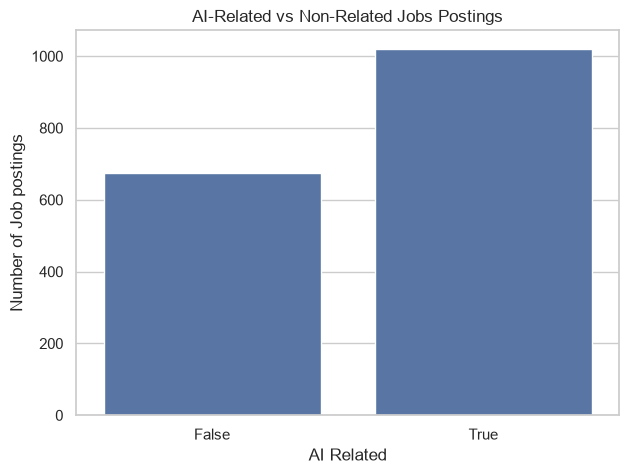

In [12]:
#Visua;ise AI-related VS non-AI related jobs

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="is_ai_related"
)
plt.title("AI-Related vs Non-Related Jobs Postings")
plt.xlabel("AI Related")
plt.ylabel("Number of Job postings")

plt.show()

## 6. Job Category Analysis

Job categories are analyzed to identify the areas with the highest number of job postings.

This analysis helps determine which types of jobs are most represented in the dataset.

In [13]:
#Count job postings by categpry

category_counts = (
    df["category"]
    .value_counts()
    .sort_values(ascending=False)
)

category_counts.head(10)

category
IT Jobs                      695
Engineering Jobs             237
Admin Jobs                   202
Customer Services Jobs       153
Sales Jobs                   133
Accounting & Finance Jobs     59
Teaching Jobs                 31
Scientific & QA Jobs          31
Part time Jobs                28
Maintenance Jobs              26
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

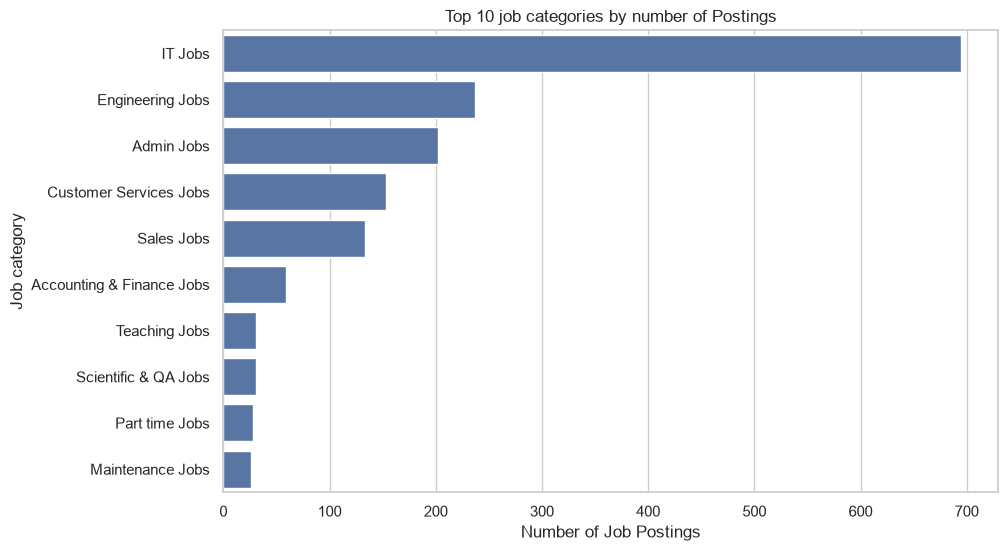

In [14]:
#Top 10 job postings

plt.figure(figsize=(10, 6))

sns.barplot(
    x = category_counts.head(10).values,
    y = category_counts.head(10).index
)

plt.title("Top 10 job categories by number of Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job category")

plt.show

## 7. Geographic Distribution

The geographic distribution of job postings is analyzed using the country-related fields in the dataset.

This helps identify which countries contribute the largest number of job postings in the dataset.

In [15]:
#job postings by country
country_counts = (
    df["country_name"]
    .value_counts()
    .sort_values(ascending=False)
)

country_counts

country_name
United States     750
United Kingdom    746
India             200
Name: count, dtype: int64

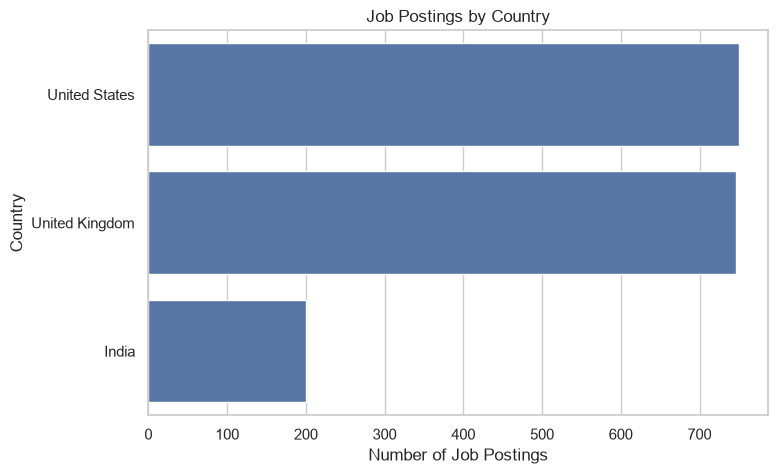

In [16]:
#Visulaize job postings by country

plt.figure(figsize=(8, 5))

sns.barplot(
    x = country_counts.values,
    y = country_counts.index
)

plt.title("Job Postings by Country")
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")

plt.show()

## 8. Contract and Employment Analysis

The dataset contains information about contract type and contract time.

These variables are analyzed to understand the employment arrangements represented in the dataset.

In [17]:
#Contact type distribution

contract_type_counts = df["contract_type"].value_counts(dropna=False)

contract_type_counts

contract_type
NaN          1264
permanent     289
contract      143
Name: count, dtype: int64

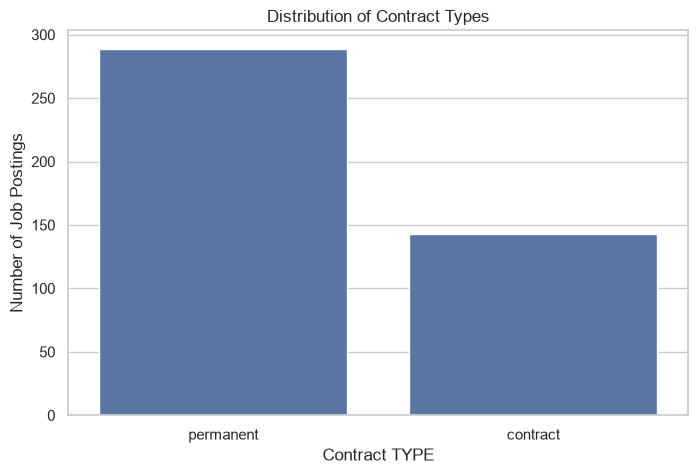

In [18]:
#Visualise contract type distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data = df,
    x = "contract_type"
)
plt.title("Distribution of Contract Types")
plt.xlabel("Contract TYPE")
plt.ylabel("Number of Job Postings")

plt.show()

In [19]:
#Contract time distribution

contract_time_counts = df["contract_time"].value_counts(dropna=False)

contract_time_counts

contract_time
NaN          870
full_time    685
part_time    141
Name: count, dtype: int64

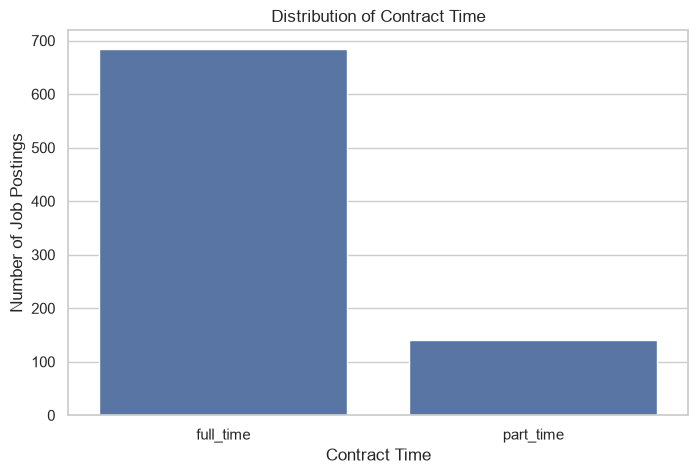

In [20]:
#Visualize contract time distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data = df,
    x = "contract_time")

plt.title("Distribution of Contract Time")
plt.xlabel("Contract Time")
plt.ylabel("Number of Job Postings")

plt.show()

## 9. Salary Analysis

Salary-related variables are analyzed to understand the distribution of compensation in the dataset.

The analysis will examine:

- Minimum salary
- Average salary
- Maximum salary
- Salary distribution
- Salary differences across countries
- Salary differences across job categories

In [21]:
#Summary statistics for salary columns

df[
    ["salary_min", "salary_avg", "salary_max"]
    ].describe()

,salary_min,salary_avg,salary_max
count,1.513000e+03,1.513000e+03,1.513000e+03
mean,7.729904e+04,8.228850e+04,8.727796e+04
std,9.713633e+04,1.375764e+05,1.836966e+05
min,0.000000e+00,1.300000e+01,1.300000e+01
25%,3.488679e+04,3.500000e+04,3.504305e+04
50%,5.460000e+04,5.500000e+04,5.514576e+04
75%,9.760078e+04,9.896877e+04,1.000000e+05
max,2.000000e+06,3.500000e+06,5.000000e+06


In [22]:
#Average salary

df["salary_avg"].mean()

np.float64(82288.50109715796)

In [23]:
#Median salary

df["salary_avg"].median()

np.float64(55000.0)

In [24]:
# Check how many job postings have salary information

salary_data = df["salary_avg"].notna().sum()
missing_salary = df["salary_avg"].isna().sum()

print("Job postings with salary information:", salary_data)
print("Job postings without salary information:", missing_salary)

salary_percentage = df["salary_avg"].notna().mean() * 100

print(f"Percentage with salary information: {salary_percentage:.2f}%")

Job postings with salary information: 1513
Job postings without salary information: 183
Percentage with salary information: 89.21%


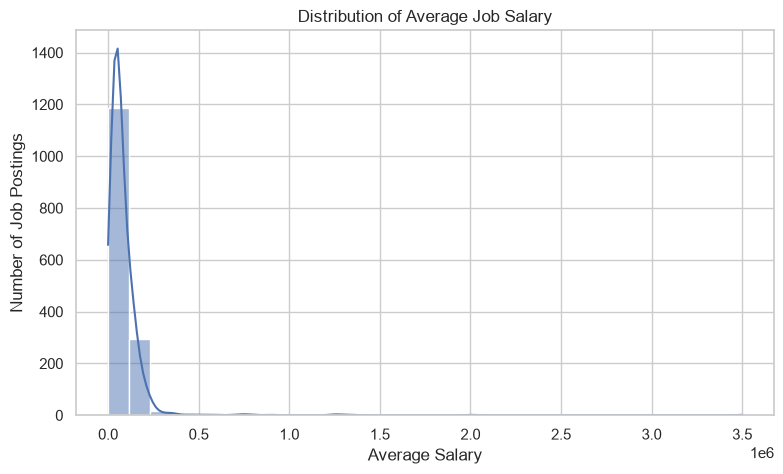

In [25]:
#Salary distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="salary_avg",
    bins=30,
    kde=True
)

plt.title("Distribution of Average Job Salary")
plt.xlabel("Average Salary")
plt.ylabel("Number of Job Postings")

plt.show()

In [26]:
#Average salary by country

salary_by_country = (
    df.groupby("country_name")["salary_avg"]
    .mean()
    .sort_values(ascending=False)
)

salary_by_country

country_name
India             992941.176471
United States      94890.683467
United Kingdom     48866.607989
Name: salary_avg, dtype: float64

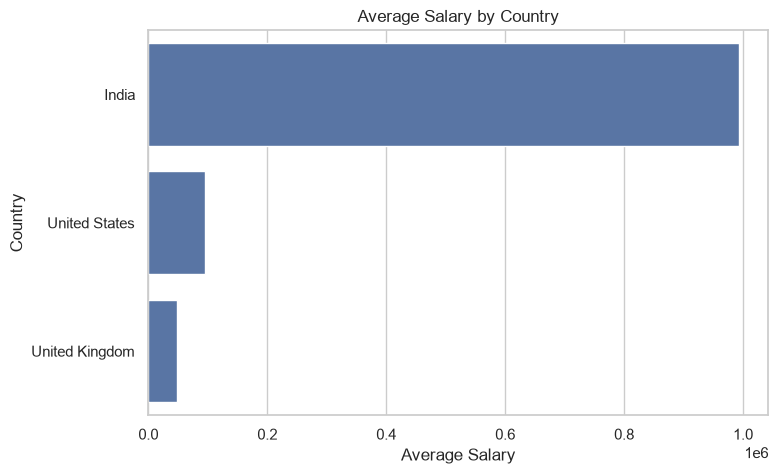

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=salary_by_country.values,
    y=salary_by_country.index
)

plt.title("Average Salary by Country")
plt.xlabel("Average Salary")
plt.ylabel("Country")

plt.show()

### Salary by AI-Related Status

Average salary is compared between AI-related and non-AI-related job postings to examine whether AI-related roles show different salary patterns.

In [28]:
#Average and median salary by AI related status

ai_salary = (
    df.groupby("is_ai_related")["salary_avg"]
    .agg(["count", "mean", "median"])
)

ai_salary

,count,mean,median
is_ai_related,,,
False,642,37217.923723,32540.91
True,871,115509.294064,83808.39


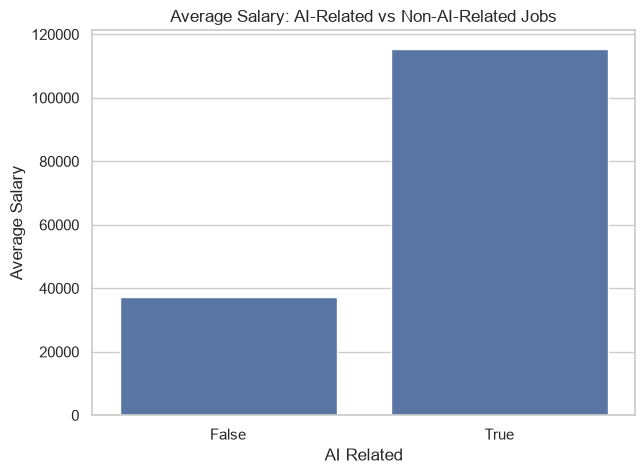

In [29]:
# Visualize average salary by AI-related status

plt.figure(figsize=(7, 5))

sns.barplot(
    x=ai_salary.index,
    y=ai_salary["mean"]
)

plt.title("Average Salary: AI-Related vs Non-AI-Related Jobs")
plt.xlabel("AI Related")
plt.ylabel("Average Salary")

plt.show()

### Salary by Job Category

Average salary is compared across job categories to identify whether compensation varies between different types of roles.

In [30]:
#Average salary by job category

salary_by_category = (
    df.groupby("category")["salary_avg"]
    .mean()
    .sort_values(ascending=False)
)

salary_by_category

category
Consultancy Jobs                    205950.083333
Scientific & QA Jobs                178072.187692
IT Jobs                             128494.492797
Engineering Jobs                     75693.579955
Manufacturing Jobs                   66573.283333
Legal Jobs                           64020.498235
Healthcare & Nursing Jobs            60207.060769
HR & Recruitment Jobs                58926.970000
Accounting & Finance Jobs            58068.956957
Teaching Jobs                        55587.822000
Trade & Construction Jobs            55389.421250
Hospitality & Catering Jobs          51119.463333
PR, Advertising & Marketing Jobs     42807.716000
Customer Services Jobs               40220.213922
Maintenance Jobs                     35497.838462
Admin Jobs                           35060.885248
Retail Jobs                          33577.017143
Logistics & Warehouse Jobs           31311.770000
Graduate Jobs                        31296.019000
Sales Jobs                           2823

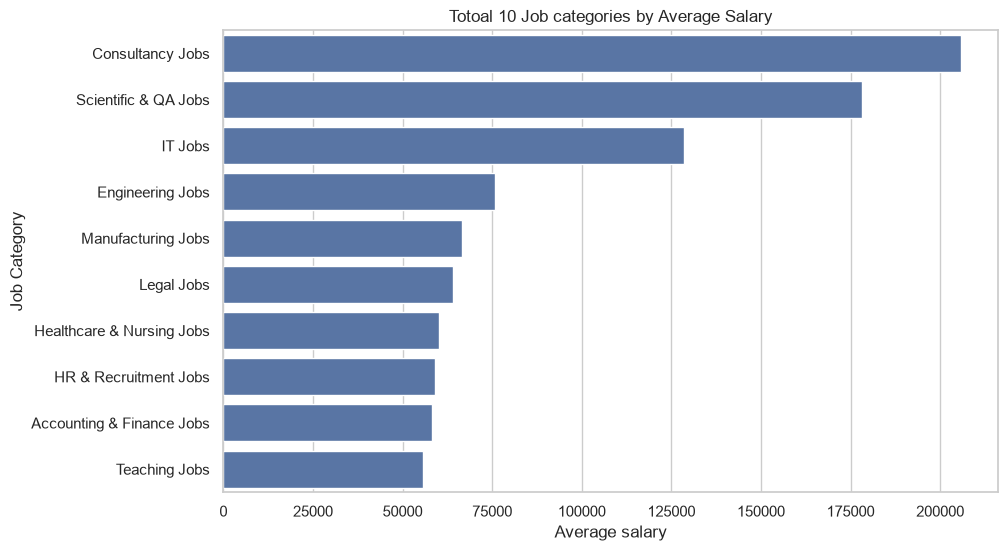

In [31]:
#Top 10 categories by average salary

top_salary_categories = salary_by_category.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x = top_salary_categories.values,
    y = top_salary_categories.index
)

plt.title("Totoal 10 Job categories by Average Salary")
plt.xlabel("Average salary")
plt.ylabel("Job Category")

plt.show()

### Salary Analysis Summary

The salary analysis shows how compensation varies across the job market. Salary distributions, country-level differences, AI-related job differences, and job category differences provide a broader understanding of compensation patterns in the dataset.

Salary comparisons are based only on job postings where salary information is available. Therefore, differences between groups should be interpreted as descriptive patterns rather than definitive conclusions about the overall job market.

In [32]:
#Salary quartiles

Q1 = df["salary_avg"].quantile(0.25)
Q3 = df["salary_avg"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

salary_outliers = df[
    (df["salary_avg"] < lower_bound) |
    (df["salary_avg"] > upper_bound)
    ]

salary_outliers.shape

(67, 19)

In [33]:
#Display the salary boundaries used for outlier detection

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 35000.0
Q3: 98968.77
IQR: 63968.770000000004
Lower Bound: -60953.155
Upper Bound: 194921.925


In [34]:
#Inspect salary outliers

salary_outliers[
    [
        "title",
        "company",
        "country_name",
        "category",
        "salary_min",
        "salary_avg",
        "salary_max",
        "is_ai_related"
    ]
    ].sort_values("salary_avg", ascending=False).head(20)

,title,company,country_name,category,salary_min,salary_avg,salary_max,is_ai_related
1575,Artificial Intelligence (AI) Specialist,Forhyre,India,IT Jobs,2000000.00,3500000.00,5000000.00,True
1574,Lead Artificial Intelligence Engineer,xpressbees,India,Scientific & QA Jobs,1500000.00,2000000.00,2500000.00,True
1534,Artificial Intelligence Architect,Mastercard,India,IT Jobs,1200000.00,1350000.00,1500000.00,True
1644,Senior Artificial intelligence/ Machine Learni...,Jobdost,India,IT Jobs,800000.00,1300000.00,1800000.00,True
1577,NLP Engineer - Artificial Intelligence,Artivatic,India,IT Jobs,1000000.00,1250000.00,1500000.00,True
1512,Artificial Intelligence,RandomTrees,India,IT Jobs,1000000.00,1250000.00,1500000.00,True
1643,Senior Artificial Intelligence/Machine Learnin...,Artivatic,India,IT Jobs,600000.00,900000.00,1200000.00,True
1529,Head - Artificial Intelligence,KGiSL Educational Institutions,India,IT Jobs,100000.00,800000.00,1500000.00,True
1642,Artificial Intelligence/NLP/Machine Learning N...,COGXIO.COM,India,IT Jobs,500000.00,750000.00,1000000.00,True
1576,NLP Engineer - Artificial Intelligence,Artivatic,India,IT Jobs,500000.00,750000.00,1000000.00,True


In [35]:
#Outliers by country

outliers_by_country = (
    salary_outliers["country_name"]
    .value_counts()
)

outliers_by_country

country_name
United States    51
India            16
Name: count, dtype: int64

In [36]:
#Compare average salary between AI-related and non AI related jobs

ai_salary_summary = df.groupby("is_ai_related")["salary_avg"].agg(
    ["count", "mean", "median"]
)

ai_salary_summary

,count,mean,median
is_ai_related,,,
False,642,37217.923723,32540.91
True,871,115509.294064,83808.39


In [37]:
#Average salary by country

salary_by_country_summary = df.groupby("country_name")["salary_avg"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

salary_by_country_summary

,count,mean,median
country_name,,,
India,17,992941.176471,750000.000
United States,750,94890.683467,78710.350
United Kingdom,746,48866.607989,44631.225


In [38]:
#Contract type distribution with percentage

contract_type_summary = pd.DataFrame({
    "Count": df["contract_type"].value_counts(dropna=False),
    "Percentage": df["contract_type"].value_counts(
        normalize = True, dropna=False
    ) * 100

})

contract_type_summary

,Count,Percentage
contract_type,,
NaN,1264,74.528302
permanent,289,17.040094
contract,143,8.431604


In [39]:
#Contract time distribution with percentages 

contract_time_summary = pd.DataFrame({
    "Count":df["contract_time"].value_counts(dropna=False),
    "Percentage": df["contract_time"].value_counts(
        normalize = True, dropna=False
    ) * 100
})

contract_time_summary

,Count,Percentage
contract_time,,
NaN,870,51.297170
full_time,685,40.389151
part_time,141,8.313679


## 10. Relationships Between Job Characteristics

This section examines relationships between important job characteristics to identify patterns that may not be visible when variables are analyzed separately.

The analysis focuses on:

- AI-related jobs across countries
- AI-related jobs across job categories
- The relationship between AI relevance and salary

In [40]:
#AI related jobs by country

ai_country = pd.crosstab(
    df["country_name"],
    df["is_ai_related"]
)

ai_country

is_ai_related,False,True
country_name,,
India,33,167
United Kingdom,341,405
United States,301,449


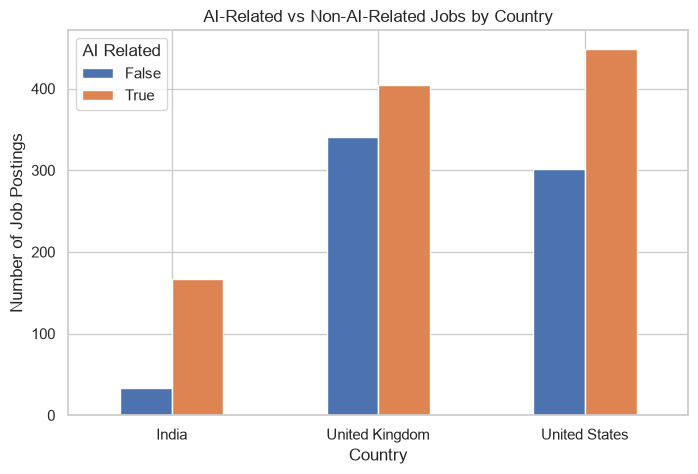

In [41]:
# Visualize AI-related and non-AI-related jobs by country

ai_country.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("AI-Related vs Non-AI-Related Jobs by Country")
plt.xlabel("Country")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=0)
plt.legend(title="AI Related")

plt.show()

### AI-Related Jobs Across Job Categories

The relationship between AI relevance and job category is examined to identify which job categories contain the highest number of AI-related job postings.

In [42]:
#AI related jobs by job categories

ai_category = pd.crosstab(
    df["category"],
    df["is_ai_related"]
)

ai_category.sort_values(
    by=True,
    ascending=False
).head(10)

is_ai_related,False,True
category,,
IT Jobs,43,652
Engineering Jobs,11,226
Scientific & QA Jobs,2,29
Sales Jobs,109,24
Teaching Jobs,11,20
Accounting & Finance Jobs,42,17
Graduate Jobs,2,8
Healthcare & Nursing Jobs,5,8
"PR, Advertising & Marketing Jobs",4,7


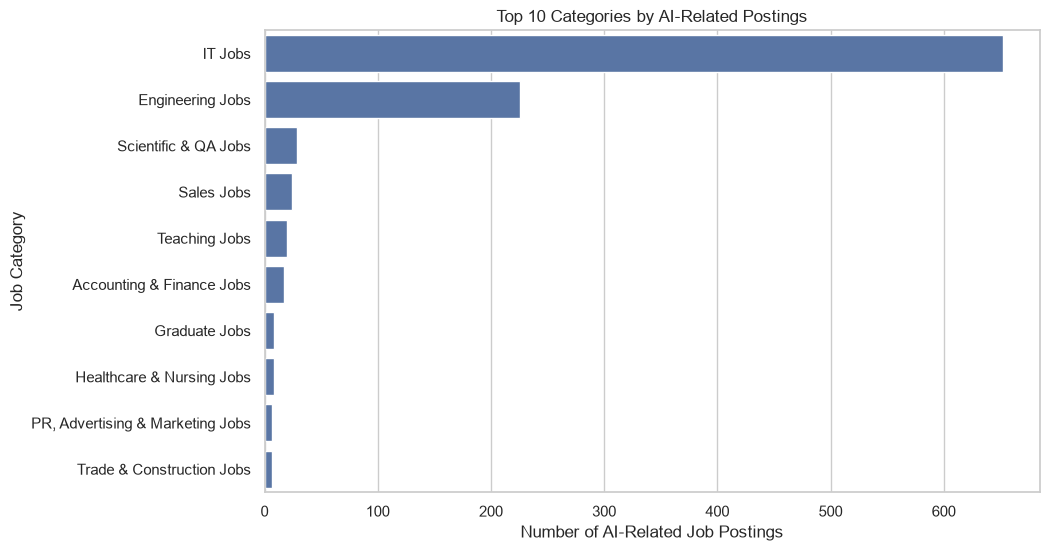

In [45]:
#Visualize the top 10 categories by AI-related job postings

top_ai_categories = (
    ai_category[True]
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_ai_categories.values,
    y=top_ai_categories.index
)

plt.title("Top 10 Categories by AI-Related Postings")
plt.xlabel("Number of AI-Related Job Postings")
plt.ylabel("Job Category")

plt.show()

### Relationship Between AI Relevance and Salary

The relationship between AI relevance and salary is examined by comparing the salary distributions of AI-related and non-AI-related job postings.

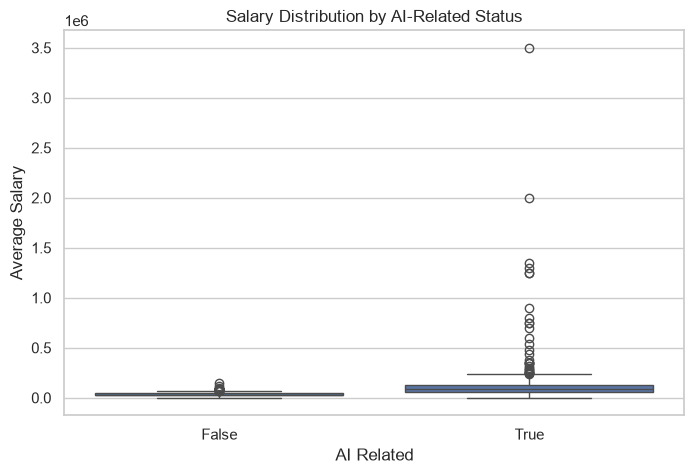

In [47]:
#Compare salary distributions by AI0related status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_ai_related",
    y="salary_avg"
)

plt.title("Salary Distribution by AI-Related Status")
plt.xlabel("AI Related")
plt.ylabel("Average Salary")

plt.show()

### Relationship Analysis Summary

The relationship analysis helps identify how AI-related jobs are distributed across countries and job categories and how salary patterns differ between AI-related and non-AI-related roles.

The salary relationship should be interpreted carefully because salary information is missing for some job postings and the dataset contains high-value salary outliers.

## 11. Key Insights

The exploratory analysis of the AI Job Market dataset revealed the following key insights:

1. **AI-related roles form a significant portion of the dataset.**  
   Out of 1,696 job postings, 1,021 were identified as AI-related, representing approximately 60.2% of all postings.

2. **IT is the largest job category.**  
   IT Jobs account for 695 postings, making them the most represented category in the dataset, followed by Engineering Jobs and Admin Jobs.

3. **Job postings are concentrated in three countries.**  
   The dataset contains 750 postings from the United States, 746 from the United Kingdom, and 200 from India. Together, these countries account for all 1,696 postings in the dataset.

4. **AI-related jobs show higher salary levels in the available salary data.**  
   Among postings with salary information, AI-related jobs have an average salary of approximately 115,509, compared with approximately 37,218 for non-AI-related jobs. The median salaries are approximately 83,808 and 32,541 respectively.

5. **Salary information is available for most job postings.**  
   1,513 of the 1,696 job postings contain salary information, representing approximately 89.21% of the dataset. The remaining 183 postings have missing salary values.

6. **Salary varies considerably across job categories.**  
   Consultancy Jobs and Scientific & QA Jobs have the highest average salaries in the dataset, while Creative & Design Jobs have no available average salary because salary information is missing for those postings.

7. **The dataset contains high-value salary outliers.**  
  Using the IQR method, 67 out of the 1,513 job postings with available salary information were identified as salary outliers, representing approximately 4.43% of salary-observed postings. These outliers were concentrated in the United States and India, with several high-paying roles being AI-related.

9. **Employment information contains substantial missing values.**  
   Contract type is missing for approximately 74.53% of postings, while contract time is missing for approximately 51.30%. Therefore, conclusions about employment arrangements should be interpreted carefully.

10. **AI-related roles are distributed across multiple job categories and countries.**  
   The relationship analysis shows that AI-related employment is not limited to a single category or country, although some categories contain substantially more AI-related postings than others.

## 12. Conclusion

This exploratory data analysis provided an overview of the AI Job Market dataset and helped identify important patterns in job postings, AI relevance, job categories, geographic distribution, employment arrangements, and salaries.

The analysis shows that AI-related jobs represent a substantial share of the dataset and generally have higher salary levels than non-AI-related roles among postings with available salary information. IT is the largest job category, while job postings are concentrated across the United States, United Kingdom, and India.

The salary analysis also highlighted substantial variation in compensation and identified several high-value salary outliers. At the same time, missing information in salary and employment-related fields limits some comparisons and should be considered when interpreting the results.

Overall, the findings provide a useful foundation for the next stage of the project, where the identified patterns can be presented through interactive visualizations and dashboards.